In [1]:
import sys

import pandas as pd
import os
# Add the parent directory to sys.path
sys.path.append(os.path.abspath('../3_src/'))

import numpy as np

import seaborn as sns
import analysis.io_func as io_func
import analysis.an_func as an_func
import matplotlib.pyplot as plt
from analysis import config_13c as config
import seaborn as sns
import analysis.io_func as io_func
import analysis.an_func as an_func
import matplotlib.pyplot as plt

from matplotlib.ticker import LogLocator

from scipy.stats import gaussian_kde
from scipy.integrate import simpson

import analysis.DistribComp as dc

/home/nathan/PhD/04.Computational/202601_13C/3_src/freeflux/src/freeflux/core/reaction.py:104: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.substrates_info = pd.concat((self.substrates_info, newSubs))
/home/nathan/PhD/04.Computational/202601_13C/3_src/freeflux/src/freeflux/core/reaction.py:132: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.products_info = pd.concat((self.products_info, newPros))
/home/nathan/PhD/04.Computational/202601_13C/3_src/freeflux/src/freeflux/core/reaction.py:

In [2]:
# Import general configs:
palette ,cfg =io_func.import_plotconfigs()

In [3]:
condition = cond = 'TM6'
color=palette[2] if condition == 'TM6' else palette[0]
palette_cond=[palette[0],palette[4],palette[1]] if condition == 'WT' else [palette[2],palette[5],palette[3]]

In [4]:
model=config.model
net_flux_df=config.full_flux_df(condition)
bootstrap_flux_df=config.bootstrap_flux_df(condition)
obj_vals=config.obj_vals(condition)
# accepted_samples=obj_vals[obj_vals<=config.find_plateau(obj_vals)].index
# len(accepted_samples)

# nperc=5
# accepted_samples=obj_vals[obj_vals<=np.percentile(obj_vals,nperc)].index
flux_file=config.flux_file(condition)


In [5]:
net_flux_df

,0,1,2,3,4,5,6,7,8,9,...,990,991,992,993,994,995,996,997,998,999
ASNS1,0.024903,0.025846,0.024704,0.024936,0.024819,0.024732,0.024674,0.024690,0.025238,0.024672,...,0.025012,0.025498,0.025042,0.024750,0.025641,0.024687,0.025660,0.026128,0.025018,0.025681
ASPK,0.111911,0.114174,0.112303,0.109130,0.109205,0.111066,0.106060,0.115099,0.111859,0.106177,...,0.109872,0.121408,0.107147,0.115795,0.110196,0.110898,0.110390,0.115463,0.118095,0.113690
ASPTA,-0.259349,-9.535355,0.971285,3.765933,-0.000499,3.143642,13.670185,14.380529,13.336353,3.564326,...,1.269875,-0.435934,1.232032,-0.007460,7.425697,-0.001950,3.256940,3.432251,-0.071347,3.932963
ASPTAm,-0.069125,9.196421,-1.298421,-4.091908,-0.324536,-3.469781,-13.990813,-14.710334,-13.667684,-3.885054,...,-1.597252,0.092791,-1.556947,-0.323561,-7.758874,-0.323627,-3.590470,-3.774927,-0.264312,-4.269979
ASAD,0.111911,0.114174,0.112303,0.109130,0.109205,0.111066,0.106060,0.115099,0.111859,0.106177,...,0.109872,0.121408,0.107147,0.115795,0.110196,0.110898,0.110390,0.115463,0.118095,0.113690
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SUCCPItm-2-2,-0.294951,-0.114989,-0.137660,-2.612360,-0.301098,-2.693176,-8.492668,-0.205608,-0.530549,-2.963066,...,-0.241505,-0.052976,-0.417320,-0.221957,-0.220403,-0.717217,-2.996849,-0.579232,-0.260468,-3.419670
SUCFUMtm-2-2,0.014583,-0.141987,-0.758219,1.797093,0.137333,1.885102,7.614247,-0.705836,-0.233802,2.099460,...,-0.635255,-0.278853,-0.453316,-0.695450,-0.566122,-0.082105,2.175921,-0.122195,0.016210,2.674118
THRtm+0,0.045570,0.047295,0.045206,0.045630,0.045416,0.045257,0.045150,0.045180,0.046182,0.045147,...,0.045769,0.046659,0.045824,0.045289,0.046921,0.045174,0.046954,0.047812,0.045781,0.046993
biomass_ce,0.244870,0.254138,0.242913,0.245189,0.244041,0.243186,0.242613,0.242770,0.248159,0.242596,...,0.245935,0.250719,0.246232,0.243358,0.252127,0.242739,0.252306,0.256914,0.246002,0.252517


## load optimal solutions from remote fitting and look at obj value

### next up is looking at flux distributions and how they vary when taking the best fitting distributions of 1-13 and of U-13


In [6]:
### take same size for net flux df than boostrap flux df
distcomp=dc.DistribComparer(net_flux_df.loc[:,np.random.choice(1000,bootstrap_flux_df.shape[1])],bootstrap_flux_df,num_points=10000)

In [7]:
serarea=distcomp.compute_overlap_all()
sermean=distcomp.get_deltamean()

In [8]:
# pd.Series(serarea).to_csv(f'{config.FREEFLUXRUN_FOLDER}/{condition}_overlaparea_nperc{nperc}.csv')

in this notebook we compare flux distributions with initial set of samples or only best.
we take the distributions, align to the same mean, and calculate the area overlap


### one reaciton plot

In [9]:
###remove rxn that have serarea >1 : numerical error, could be avoided with numpoints >=1e6
serarea = {k: v for k, v in serarea.items() if v < 1}
ser_area_opp=pd.Series([1-x for x in pd.Series(serarea)],index=pd.Series(serarea).index)

In [10]:
# serareaopptm6=ser_area_opp
## to get two conds plots i run tm6 first then switch cond to wt . TODO make better notebook

In [11]:
pd.Series(serarea).sort_values(ascending=False).head(50)#.index

PPAm            0.878709
ACSm            0.878709
ADK1m           0.878709
OAAtm-2+H       0.862277
3MOPtm-1+H      0.828184
3MOPtm-1        0.828165
PYRDC           0.817734
PYRt-1          0.811043
PYRt-1+H        0.807087
POSQt           0.806241
IONPUMP         0.804199
ICL             0.801160
ADPATPtm-4-2    0.795880
2OBUTtm-1+H     0.794319
2OBUTtm-1       0.794318
MALS            0.785829
NH3t+1          0.780669
NH3t+1-H        0.767661
CO2tm-1+H       0.765623
ACOAH           0.765558
GLXtm-1         0.756450
GLXtm-1+H       0.756165
ORNtm+1-H       0.755228
ORNtm+1         0.754869
ALDD2xm         0.754327
3MOBtm-1+H      0.754081
3MOBtm-1        0.753602
ALDD2y          0.748990
Htm             0.745013
pyr_EX          0.742837
ACtm-1          0.740037
gmpSYN1         0.738752
ampSYN2         0.737444
PPA             0.735425
TYRTA           0.734811
gmpSYN2         0.733125
ACONT           0.725819
ALAtm+0         0.722486
ALATA_L         0.721758
ampSYN1         0.721459


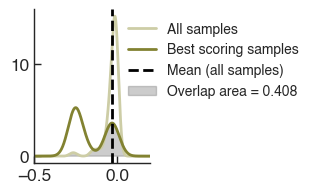

In [ ]:
fig,ax=plt.subplots(1,1,figsize=(1.5,2))
io_func.scale_rcparams(fig,scalingf=0.5)
rxn='MDH'
distcomp.plot_reaction(ax,rxn,align=False,colors=[palette[3],palette[2]])
ax.set_xlim(-0.5,0.2)
ax.legend(frameon=False,bbox_to_anchor=(0.7, 1), loc='upper left',fontsize=10)
##3 yticks
ax.locator_params(axis='both', nbins=2)
# ax.set_xticks([0,3])

##savefig
# plt.savefig(f'{config.PLOTS_FOLDER}/fig4_{condition}_overlaparea_example{rxn}_bootstrap.png',dpi=300,bbox_inches='tight')
# plt.savefig(f'{config.PLOTS_FOLDER}/fig4_{condition}_overlaparea_example{rxn}_bootstrap.svg',dpi=300,bbox_inches='tight')

## global plot ; bootstrap top 2 vs bootstrap random

In [ ]:
# boostraprandom_flux_df=pd.read_csv(f'{config.FREEFLUXRUN_FOLDER}/weighted_randombootstrap_flux_df_{condition}.csv',index_col=0)
# boostraprandom_flux_df.columns=[int(x) for x in boostraprandom_flux_df.columns]

In [ ]:
# distcomp_control=dc.DistribComparer(bootstrap_flux_df,boostraprandom_flux_df,num_points=10000)
# serarea_control=distcomp_control.compute_overlap_all()

In [ ]:
# ## calc complement of overlap area
# serarea_control = {k: v for k, v in serarea_control.items() if v < 1}
# serarea_oppcontrol=pd.Series([1-x for x in pd.Series(serarea_control)],index=pd.Series(serarea_control).index)


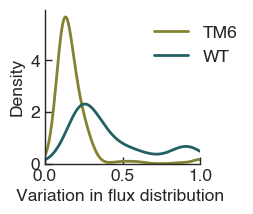

In [ ]:
fig,ax=plt.subplots(1,1,figsize=(2,2))
io_func.scale_rcparams(fig,scalingf=0.5)

# sns.kdeplot(serarea_oppcontrol,label=f'random bootstrap',linewidth=2,clip=(0, 1),color=palette_cond[1])

sns.kdeplot(ser_area_opp,label=f'TM6',linewidth=2,clip=(0, 1),color=palette[2])
sns.kdeplot(serareaopptm6,label=f'WT',linewidth=2,clip=(0, 1),color=palette_cond[0])
# sns.histplot(ser_area_opp,label=f'top 2% bootstrap',color=palette_cond[0])

ax.legend(frameon=False, bbox_to_anchor=(0.6, 1), loc='upper left')
ax.set_xlabel('Variation in flux distribution ')
ax.set_xlim(0,1)

# plt.savefig(f'{config.PLOTS_FOLDER}/fig5d_{condition}overlaparea_bootstrap_2conds.svg', dpi=300, bbox_inches='tight')

In [ ]:

distcomp_rand=dc.DistribComparer(net_flux_df.loc[:,np.random.choice(1000,bootstrap_flux_df.shape[1])],boostraprandom_flux_df,num_points=10000)
serarea_rand=distcomp_rand.compute_overlap_all()


In [77]:
## calc complement of overlap area
serarea_rand = {k: v for k, v in serarea_rand.items() if v < 1}
serarea_opprand=pd.Series([1-x for x in pd.Series(serarea_rand)],index=pd.Series(serarea_rand).index)


In [78]:
serarea_rand

{'ASNS1': 0.6943212054918776,
 'ASPK': 0.7840084886841029,
 'ASPTA': 0.6935752963359605,
 'ASPTAm': 0.6927693442084455,
 'ASAD': 0.784008488684075,
 'ALATA_L': 0.46712285243733226,
 'ALATA_Lm': 0.46556609155665996,
 'GLCS2': 0.38286589195197346,
 'PGMT': 0.5183823359742744,
 'GALU': 0.504154434600415,
 'FBP': 0.552129708341138,
 'ICL': 0.6115122003615144,
 'MALS': 0.6122190740186123,
 'MEm': 0.5776915246266926,
 'PPCK': 0.4949311369364775,
 'PC': 0.6239145464387352,
 'ACGKm': 0.6810479622940143,
 'ACOTAm': 0.6810479622936845,
 'ARGSL': 0.6810479622934172,
 'ARGSS': 0.6810479622935394,
 'CBPS': 0.6810479622928582,
 'GLU5K': 0.6788040605711373,
 'G5P5': 0.678804060571269,
 'AGPRm': 0.6810479622944748,
 'OCBT': 0.6810479622931017,
 'ORNTACm': 0.6810479622932856,
 'ampSYN1': 0.5662802283890244,
 'ampSYN2': 0.5585233416143824,
 'cmpSYN': 0.6063785612242201,
 'dampSYN': 0,
 'dcmpSYN': 0,
 'dgmpSYN': 0,
 'dtmpSYN': 0,
 'ergstSYN': 0,
 'gmpSYN1': 0.5591002408985417,
 'gmpSYN2': 0.5627313224478

## look at pathways with most variation

In [12]:
pathways_mapping=pd.read_csv(f'{config.SYNDATA_FOLDER}/pathways_mapping.csv',index_col=0)
###replace biomass synthesis with biosynthesis in the dict
pathways_mapping = (
    pathways_mapping.Subsystem
    .str.replace(r"^Transport,.*", "Transport", regex=True)
    .replace("Biomass synthesis", "Biosynthesis")
)

In [13]:
df_serareaopp=pd.DataFrame(ser_area_opp,columns=['variation'])
for rxn in [r for r in df_serareaopp.index.intersection(pathways_mapping.index)]:
    df_serareaopp.loc[rxn,'Subystem']=pathways_mapping.loc[rxn]



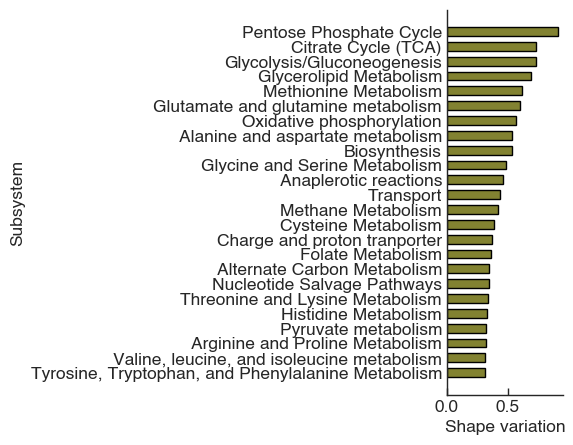

In [ ]:
##average by subsystem
df_avg_sub=df_serareaopp.groupby("Subystem")["variation"].mean().sort_values(ascending=False).copy()#.head(5)

fig,ax=plt.subplots(1,1,figsize=(1.5,5))
io_func.scale_rcparams(fig,scalingf=0.5)
ax.barh(df_avg_sub.index, df_avg_sub.values,edgecolor='black',height=0.6,color=palette[2])
plt.gca().invert_yaxis()  # highest at top

plt.xlabel("Shape variation")
plt.ylabel("Subsystem")
# plt.xlim(0,1)
##shorten ylabls 
# ax.set_yticklabels(['PPP', 'TCA', 'Glycolysis', 'Glycerolipid', 'Ox. phos.',],fontsize=12) 
##save fig 
# plt.savefig(f'{config.PLOTS_FOLDER}/fig5e_{condition}_allsubsystems_overlaparea_bootstrap.png', dpi=300, bbox_inches='tight')
# plt.savefig(f'{config.PLOTS_FOLDER}/fig5e_{condition}_allsubsystems_overlaparea_bootstrap.svg', dpi=300, bbox_inches='tight')

#### same but with EMD

In [17]:
ser_emd=distcomp.compute_EMD_all()

In [18]:
df_emd=pd.DataFrame(pd.Series(ser_emd))#,columns=['emd'])
for rxn in [r for r in df_emd.index.intersection(pathways_mapping.index)]:
    df_emd.loc[rxn,'Subystem']=pathways_mapping.loc[rxn]
df_emd.columns=['EMD','Subystem']


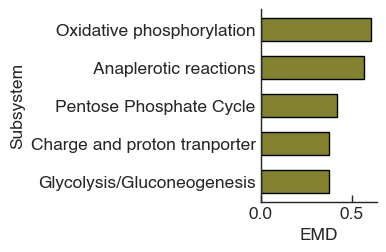

In [ ]:
##average by subsystem
df_avgemd_sub=df_emd.groupby("Subystem")["EMD"].mean().sort_values(ascending=False).copy().head(5)

fig,ax=plt.subplots(1,1,figsize=(1.5,2.5))
io_func.scale_rcparams(fig,scalingf=0.5)
ax.barh(df_avgemd_sub.index, df_avgemd_sub.values,edgecolor='black',height=0.6,color=palette[2])
plt.gca().invert_yaxis()  # highest at top

plt.xlabel("EMD")
plt.ylabel("Subsystem")
##shorten ylabls 
# ax.set_yticklabels(['PPP', 'TCA', 'Glycolysis', 'Glycerolipid', 'Ox. phos.'],fontsize=12) 
# ##save fig 
# plt.savefig(f'{config.SUPP_PLOTS_FOLDER}/fig5Supp_{condition}_subsystems_EMD_bootstrap.png', dpi=300, bbox_inches='tight')
# plt.savefig(f'{config.SUPP_PLOTS_FOLDER}/fig5SUpp_{condition}_subsystems_EMD_bootstrap.svg', dpi=300, bbox_inches='tight')